# BERTopic

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pathlib import Path
from IPython.display import display
from tqdm.auto import tqdm

from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModel
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

c:\Users\caral\OneDrive\Documents\SCI501\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# Define the condition we want to analyse
CONDITION = "aig"

# Set the folder where the processed files are stored
DATA_DIR = Path(f"pmc/{CONDITION}/processed")

# Set the folder where BERTopic results will be saved
TOPIC_DIR = DATA_DIR / "bertopic"

# Create the folder if it does not already exist
TOPIC_DIR.mkdir(parents=True, exist_ok=True)

# Set the paths for the article and passage files
article_file = DATA_DIR / "articles.parquet"
passage_file = DATA_DIR / "passages.parquet"

# Check whether both processed files exist
# If either file is missing, stop and show an error
if not (article_file.exists() and passage_file.exists()):
    raise FileNotFoundError(
        f"{CONDITION} processed parquet files not found. Run data_pipeline.ipynb "
        "from the same working directory first."
    )

# Load the article and passage data into pandas DataFrames
articles_df = pd.read_parquet(article_file)
passages_df = pd.read_parquet(passage_file)

# Print the total number of articles and passages loaded
print(f"Articles: {len(articles_df)}; passages: {len(passages_df)}")


Articles: 152; passages: 4131


In [3]:
# Set the minimum number of words a passage must contain
# This removes very short passages that may not provide enough context
MIN_WORDS = 30

# Set the maximum number of passages to include from each article
# Use None to keep all passages
MAX_PASSAGES_PER_ARTICLE = None

# Set a random seed so results can be reproduced
SEED = 42

# Set the number of years to include in each time period
# This will be used to analyse how topics change over time
PERIOD_YEARS = 5

In [4]:
# Set the paths for the processed article and passage files
articles_path = DATA_DIR / "articles.parquet"
passages_path = DATA_DIR / "passages.parquet"

# Check whether both files exist
# Stop the code if either file is missing
if not articles_path.exists() or not passages_path.exists():
    raise FileNotFoundError(
        f"Couldn't find articles.parquet or passages.parquet in {DATA_DIR}. "
        "Run the data pipeline notebook first."
    )

# Load the article and passage data
articles = pd.read_parquet(articles_path)
passages = pd.read_parquet(passages_path)

# Define the columns needed for BERTopic analysis
need_articles = {"pmcid", "year"}
need_passages = {"pmcid", "passage_id", "section", "type", "text"}

# Check whether the article data contains the required columns
# Stop if any columns are missing
if missing := need_articles.difference(articles.columns):
    raise ValueError(f"Missing article columns: {sorted(missing)}")

# Check whether the passage data contains the required columns
# Stop if any columns are missing
if missing := need_passages.difference(passages.columns):
    raise ValueError(f"Missing passage columns: {sorted(missing)}")

# Remove duplicate articles based on their PMC ID
# This ensures each article only appears once
articles = articles.drop_duplicates(subset=["pmcid"]).copy()

# Convert publication years into numbers
# If a year is missing or invalid, store it as NaN
articles["year"] = pd.to_numeric(articles["year"], errors="coerce")

# Print the total number of unique articles and passages
print("Articles:", articles["pmcid"].nunique())
print("Passages:", len(passages))

# Check how many articles have missing publication years
print("Articles missing a year:", articles["year"].isna().sum())

# Show the 15 most common section names in the dataset
display(passages["section"].value_counts(dropna=False).head(15))


Articles: 152
Passages: 4131
Articles missing a year: 0


section
Discussion                                                                                                                                      534
Introduction                                                                                                                                    237
Abstract                                                                                                                                        164
1. Introduction                                                                                                                                 114
Review                                                                                                                                          105
4. Discussion                                                                                                                                    80
3. Discussion                                                                                           

In [5]:
# Remove extra spaces and line breaks from the text
# This makes the passages easier to process
def normalise_text(value):
    return re.sub(r"\s+", " ", str(value) if pd.notna(value) else "").strip()


In [6]:
# Create a function to prepare the article passages for BERTopic
# Keep the PMC ID and passage ID so results can be linked to original articles
def prepare_passages(article_table, passage_table):

    # Combine the passage data with the publication years
    df = (
        passage_table.drop(columns=["year"], errors="ignore")
        .merge(
            article_table[["pmcid", "year"]],
            on="pmcid",
            how="left",
            validate="many_to_one"
        )
    )

    # Clean the section names and passage types
    df["section"] = df["section"].fillna("UNKNOWN").astype(str)
    df["type"] = df["type"].fillna("").astype(str).str.lower()

    # Remove extra spaces from the passage text
    df["model_text"] = df["text"].map(normalise_text)

    # Count how many words are in each passage
    df["word_count"] = df["model_text"].str.split().str.len()

    # Keep passages from all sections of the article
    # Exclude headings, empty passages, short passages and invalid years
    df = df.loc[
        ~df["type"].str.startswith("title")
        & df["year"].between(1850, 2100)
        & df["word_count"].ge(MIN_WORDS)
    ].copy()

    # Convert the publication year into an integer
    df["year"] = df["year"].astype(int)

    # Remove duplicate passages from the same article
    df = df.drop_duplicates(subset=["pmcid", "model_text"])

    # Limit the number of passages taken from each article
    # This prevents longer articles from contributing too many passages
    if MAX_PASSAGES_PER_ARTICLE is not None:

        if MAX_PASSAGES_PER_ARTICLE < 1:
            raise ValueError("MAX_PASSAGES_PER_ARTICLE must be positive or None")

        df = (
            df.sample(frac=1, random_state=SEED)
            .groupby("pmcid", sort=False)
            .head(MAX_PASSAGES_PER_ARTICLE)
        )

    # Sort the passages by article and passage ID
    df = df.sort_values(["pmcid", "passage_id"]).reset_index(drop=True)

    # Group publication years into time periods
    # This allows topic trends to be analysed over time
    if not df.empty:

        df["period_start"] = (df["year"] // PERIOD_YEARS) * PERIOD_YEARS

        df["period"] = (
            df["period_start"].astype(str) + "–" +
            (df["period_start"] + PERIOD_YEARS - 1).astype(str)
        )

    return df


# Prepare the passages for BERTopic modelling
corpus = prepare_passages(articles, passages)

# Print the number of passages and articles included
print("Model passages:", len(corpus))
print("Articles represented:", corpus["pmcid"].nunique() if not corpus.empty else 0)

# Stop if there are too few passages for meaningful analysis
if len(corpus) < 30:
    raise ValueError(
        "Under 30 usable passages. Check MIN_WORDS and your input files."
    )

# Count the number of articles and passages in each time period
year_coverage = (
    corpus.groupby(["period_start", "period"], as_index=False)
    .agg(
        articles=("pmcid", "nunique"),
        passages=("pmcid", "size")
    )
)

# Display the time period coverage and example passages
display(year_coverage)
display(corpus[["pmcid", "passage_id", "year", "section", "model_text"]].head(3))

# Save the prepared corpus and time period summary
corpus.to_csv(TOPIC_DIR / "modelling_corpus.csv", index=False)
year_coverage.to_csv(TOPIC_DIR / "data_coverage_by_period.csv", index=False)

Model passages: 3717
Articles represented: 152


,period_start,period,articles,passages
0,1990,1990–1994,1,1
1,2005,2005–2009,1,25
2,2010,2010–2014,7,217
3,2015,2015–2019,31,595
4,2020,2020–2024,81,2006
5,2025,2025–2029,31,873


,pmcid,passage_id,year,section,model_text
0,PMC10052490,1,2023,Abstract,We report an unusual case of autoimmune gastri...
1,PMC10052490,2,2023,Introduction,"Autoimmune gastritis (AIG), an immune-mediated..."
2,PMC10052490,3,2023,Case report,A 60-year-old man with no family history was a...


In [7]:
PATTERN = (
    r"diagnos\w*|criteri\w*|histolog\w*|"
    r"biops\w*|atroph\w*|autoantibod\w*|"
    r"parietal cell|intrinsic factor|"
    r"pepsinogen|gastrin|endoscop\w*|serolog\w*"
)

In [8]:
# Set whether to filter articles and passages using diagnostic terminology
# True uses the diagnostic patterns, while False keeps all text
USE_PATTERN = False

# Create a function to select text containing diagnostic terminology
# This can be used for both passage-level and article-level BERTopic
def filter_diagnostic_text(df, patterns, text_column="model_text", min_words=30):

    # Remove records with missing text
    diagnostic_df = df.dropna(subset=[text_column]).copy()

    # Check whether diagnostic pattern filtering is enabled
    if USE_PATTERN:

        # Combine the diagnostic patterns if they are stored in a dictionary
        # If the pattern is already a string, use it directly
        if isinstance(patterns, dict):
            diagnostic_pattern = "|".join(
                f"(?:{pattern})" for pattern in patterns.values()
            )
        else:
            diagnostic_pattern = patterns

        # Select records that mention at least one diagnostic category
        diagnostic_df = diagnostic_df[
            diagnostic_df[text_column].str.contains(
                diagnostic_pattern,
                case=False,
                regex=True,
                na=False
            )
        ].copy()

    # Count the number of words in each record
    diagnostic_df["word_count"] = (
        diagnostic_df[text_column].str.split().str.len()
    )

    # Remove records that do not meet the minimum word count
    diagnostic_df = diagnostic_df[
        diagnostic_df["word_count"] >= min_words
    ].reset_index(drop=True)

    # Print how many records and unique articles were selected
    print("Diagnostic candidates:", len(diagnostic_df))
    print("Articles represented:", diagnostic_df["pmcid"].nunique())

    return diagnostic_df


In [9]:
# Select diagnostic passages for BERTopic
diagnostic_corpus = filter_diagnostic_text(
    corpus,
    PATTERN,
    text_column="model_text",
    min_words=MIN_WORDS
)

Diagnostic candidates: 3717
Articles represented: 152


In [10]:
# Remove generic terminology
# These words are common across articles and may not help identify topics
DOMAIN_STOPWORDS = {
    "patient", "patients",
    "study", "studies",
    "group", "groups",
    "results",
    "aig", "aag"
}

In [11]:
# Create a function to set up the components needed for BERTopic
# This can be used for both passage-level and article-level modelling
def setup_bertopic(
    df,
    text_column="model_text",
    use_medcpt_query=False,
    use_medcpt_article=False,
    domain_stopwords=None,
    seed=42,
    batch_size=8
):

    # Check that only one MedCPT encoder has been selected
    if use_medcpt_query and use_medcpt_article:
        raise ValueError("Choose only one MedCPT encoder.")

    # Check that the text column exists and contains usable text
    if text_column not in df.columns:
        raise ValueError(f"Missing text column: {text_column}")

    if df[text_column].isna().any() or df[text_column].astype(str).str.strip().eq("").any():
        raise ValueError("Remove empty text before setting up BERTopic.")

    # Convert the text into a list of documents
    texts = df[text_column].astype(str).tolist()

    # Stop if there are too few documents for topic modelling
    if len(texts) < 20:
        raise ValueError(
            "Too few documents for topic modelling."
        )

    # Set up the embedding model
    embeddings = None
    encoder = None

    # Use MedCPT if either encoder has been selected
    if use_medcpt_query or use_medcpt_article:

        # Select the MedCPT encoder
        if use_medcpt_article:
            model_name = "ncbi/MedCPT-Article-Encoder"
            max_length = 512

            # Check that article titles and abstracts are available
            if not {"title", "abstract"}.issubset(df.columns):
                raise ValueError("MedCPT Article requires title and abstract columns.")

            # Combine article titles and abstracts into pairs
            input_texts = df[["title", "abstract"]].fillna("").astype(str).values.tolist()

        else:
            model_name = "ncbi/MedCPT-Query-Encoder"
            max_length = 64

            # Use individual passages as input
            input_texts = texts

        # Load the selected MedCPT model
        tokenizer = AutoTokenizer.from_pretrained(model_name)
        medcpt_encoder = AutoModel.from_pretrained(model_name)

        # Use a GPU if available, otherwise use the CPU
        device = torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        medcpt_encoder = medcpt_encoder.to(device).eval()

        # Create a list to store the embeddings
        all_embeddings = []

        # Go through the documents in batches
        for start in tqdm(range(0, len(input_texts), batch_size)):

            batch = input_texts[start:start + batch_size]

            # Convert the text into tokens
            inputs = tokenizer(
                batch,
                truncation=True,
                padding=True,
                max_length=max_length,
                return_tensors="pt"
            )

            inputs = {
                key: value.to(device)
                for key, value in inputs.items()
            }

            # Generate embeddings without updating the model
            with torch.no_grad():
                vecs = medcpt_encoder(
                    **inputs
                ).last_hidden_state[:, 0, :]

            all_embeddings.append(vecs.cpu().numpy())

        # Combine embeddings from all batches
        embeddings = np.vstack(all_embeddings)

    else:

        # Use MiniLM as the default embedding model
        model_name = "sentence-transformers/all-MiniLM-L6-v2"

        # Load MiniLM to generate embeddings during BERTopic fitting
        encoder = SentenceTransformer(model_name)

    # Set up UMAP to reduce the size of the embeddings
    # This helps BERTopic group similar documents together
    umap_model = UMAP(
        n_neighbors=min(15, len(texts) - 1),
        n_components=5,
        metric="cosine",
        min_dist=0.0,
        random_state=seed,
        low_memory=True
    )

    # Set the minimum number of documents needed to form a topic
    min_cluster = max(5, min(15, len(texts) // 30))

    # Set up HDBSCAN to group similar documents into topics
    hdbscan_model = HDBSCAN(
        min_cluster_size=min_cluster,
        min_samples=2,
        metric="euclidean",
        prediction_data=True
    )

    # Preserve medical negations
    # Words such as "no" and "not" may change diagnostic meaning
    stop_words = set(ENGLISH_STOP_WORDS) - {
        "no", "not", "nor"
    }

    # Add any domain-specific stopwords
    # These remove common terms that may not help identify topics
    if domain_stopwords is not None:
        stop_words = stop_words | set(domain_stopwords)

    # Combine the stopwords into a sorted list
    stop_words = sorted(stop_words)

    # Set up the vectorizer to identify important words and phrases
    # Include individual words and two-word combinations
    vectorizer = CountVectorizer(
        stop_words=stop_words,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.85
    )

    # Print which embedding model is being used
    print("Embedding model:", model_name)

    # Return the components needed to create the BERTopic model
    return texts, encoder, umap_model, hdbscan_model, vectorizer, min_cluster, embeddings


In [12]:
# Choose which embedding model to use
# If both are False, MiniLM will be used
USE_MEDCPT_QUERY = True
USE_MEDCPT_ARTICLE = False

# Set the number of documents processed in each batch
BATCH_SIZE = 8

# Set the random seed so results can be reproduced
SEED = 123

In [13]:
# Set up BERTopic using diagnostic passages
texts, encoder, umap_model, hdbscan_model, vectorizer, min_cluster, embeddings = setup_bertopic(
    diagnostic_corpus,
    text_column="model_text",
    use_medcpt_query=USE_MEDCPT_QUERY,
    use_medcpt_article=USE_MEDCPT_ARTICLE,
    domain_stopwords=DOMAIN_STOPWORDS,
    seed=SEED,
    batch_size=BATCH_SIZE
)

100%|██████████| 465/465 [06:21<00:00,  1.22it/s]


Embedding model: ncbi/MedCPT-Query-Encoder


In [16]:
# Create a function to fit BERTopic and assign topics
# This can be used for both passage-level and article-level modelling
def fit_bertopic(df, texts, encoder, umap_model, hdbscan_model, vectorizer, embeddings=None):

    # Create the BERTopic model using the selected components
    model = BERTopic(
        embedding_model=encoder,
        umap_model=umap_model,
        hdbscan_model=hdbscan_model,
        vectorizer_model=vectorizer,
        calculate_probabilities=False,
        verbose=True
    )

    # Fit BERTopic using the text documents
    # Use existing embeddings if they have already been generated
    if embeddings is not None:
        topics, _ = model.fit_transform(texts, embeddings)
    else:
        topics, _ = model.fit_transform(texts)

    # Save the assigned topics to the modelling dataset
    # Keep the original data unchanged
    result_df = df.copy()
    result_df["topic"] = [int(t) for t in topics]

    # Return the model and the dataset containing assigned topics
    return model, result_df


In [15]:
# Fit BERTopic and assign a topic to each diagnostic passage
model, diagnostic_corpus = fit_bertopic(
    diagnostic_corpus,
    texts,
    encoder,
    umap_model,
    hdbscan_model,
    vectorizer
)

2026-11-10 09:32:19,776 - BERTopic - Embedding - Transforming documents to embeddings.
Batches: 100%|██████████| 117/117 [05:35<00:00,  2.87s/it]
2026-11-10 09:37:57,713 - BERTopic - Embedding - Completed ✓
2026-11-10 09:37:57,726 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-10 09:39:05,118 - BERTopic - Dimensionality - Completed ✓
2026-11-10 09:39:05,120 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-10 09:39:05,327 - BERTopic - Cluster - Completed ✓
2026-11-10 09:39:05,357 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-10 09:39:06,921 - BERTopic - Representation - Completed ✓


In [17]:
# Create a function to evaluate the BERTopic results
# This can be used for both passage-level and article-level modelling
def evaluate_bertopic(df, model, min_cluster, level="passage"):

    # Count how many topics were discovered
    # Exclude topic -1, which represents outlier documents
    n_topics = df.loc[
        df["topic"] != -1, "topic"
    ].nunique()

    # Calculate the percentage of documents assigned as outliers
    outlier_rate = (
        df["topic"] == -1
    ).mean() * 100

    # Print the main BERTopic results
    print(f"\nDiscovered topics: {n_topics}")
    print(f"Outlier {level}s: {outlier_rate:.1f}%")
    print(f"HDBSCAN min_cluster_size: {min_cluster}")

    # Show how many documents were assigned to each topic
    print("\nTopic distribution:")
    print(df["topic"].value_counts().sort_index())

    # Show how many unique articles are represented in each topic
    print("\nArticles represented per topic:")
    print(
        df.groupby("topic")["pmcid"].nunique()
    )

    # Display the topic information and most important words
    display(model.get_topic_info())

    # Return the number of topics and percentage of outliers
    return n_topics, outlier_rate


In [18]:
# Evaluate the passage-level BERTopic results
n_topics, outlier_rate = evaluate_bertopic(
    diagnostic_corpus,
    model,
    min_cluster,
    level="passage"
)


Discovered topics: 74
Outlier passages: 19.9%
HDBSCAN min_cluster_size: 15

Topic distribution:
topic
-1     740
 0     349
 1     153
 2     138
 3     132
      ... 
 69     15
 70     15
 71     15
 72     15
 73     15
Name: count, Length: 75, dtype: int64

Articles represented per topic:
topic
-1     139
 0      83
 1      58
 2      42
 3       4
      ... 
 69     10
 70      3
 71      3
 72      1
 73      3
Name: pmcid, Length: 75, dtype: int64


,Topic,Count,Name,Representation,Representative_Docs
0,-1,740,-1_pylori_autoimmune gastritis_cells_atrophic,"[pylori, autoimmune gastritis, cells, atrophic...",[Autoimmune gastritis is characterized by the ...
1,0,349,0_b12_vitamin_vitamin b12_deficiency,"[b12, vitamin, vitamin b12, deficiency, anemia...",[The most common causes of vitamin B12 deficie...
2,1,153,1_disease_thyroid_diseases_autoimmune diseases,"[disease, thyroid, diseases, autoimmune diseas...",[Polyglandular autoimmune syndromes (PAS) are ...
3,2,138,2_risk_lesions_gc_cancer,"[risk, lesions, gc, cancer, amag, gastric canc...",[There are several limitations to note in this...
4,3,132,3_malabsorption_cd_intestinal_bowel,"[malabsorption, cd, intestinal, bowel, nutriti...","[Malabsorption is a complex syndrome, with mul..."
...,...,...,...,...,...
70,69,15,69_metaplasia_intestinal_cells_pseudopyloric,"[metaplasia, intestinal, cells, pseudopyloric,...",[Autoimmune gastritis (AIG) is an organ-specif...
71,70,15,70_symptom_foods_symptoms_gastrointestinal,"[symptom, foods, symptoms, gastrointestinal, m...",[This review article aims to provide a compreh...
72,71,15,71_mag_8ohdg_eclh_stages,"[mag, 8ohdg, eclh, stages, aopps, compared, ol...",[Table 1 summarizes the AAG to MAG comparison....
73,72,15,72_er_stress_er stress_epithelial,"[er, stress, er stress, epithelial, autophagy,...",[An integrative therapeutic approach could als...


In [19]:
passage_model = model
passage_n_topics = n_topics

In [20]:

# Create a function to visualise and inspect BERTopic results
# This can be used for both passage-level and article-level modelling
def inspect_bertopic(model, n_topics, model_name="BERTopic"):

    # Show which model is being inspected
    print(f"\n{'=' * 50}")
    print(f"MODEL: {model_name}")
    print(f"{'=' * 50}")

    # Create a bar chart showing the most important words in each topic
    if n_topics > 0:
        display(
            model.visualize_barchart(
                top_n_topics=min(8, n_topics),
                n_words=10
            )
        )
    else:
        print("No non-outlier topics found.")

    # Go through each topic and display representative documents
    for topic_id in model.get_topic_info()["Topic"]:

        # Skip topic -1 because it contains outlier documents
        if topic_id == -1:
            continue

        print(f"\n{'=' * 40}")
        print(f"TOPIC {topic_id}")

        # Get example passages or articles that represent the topic
        examples = model.get_representative_docs(topic_id)

        # Display up to three examples for each topic
        if examples:
            for example in examples[:3]:
                print(example[:500])
                print()


In [22]:
# Visualise the topics and inspect representative passages
inspect_bertopic(
    passage_model,
    passage_n_topics,
    model_name="Passage"
)


MODEL: Passage



TOPIC 0
The most common causes of vitamin B12 deficiency include gastrointestinal surgery (gastric bypass, ileal resection) and dietary insufficiency and less commonly from autoimmune pernicious anemia [3]. Less commonly, nitrous oxide can cause acute depletion of vitamin B12, where the majority of etiologies are chronic in nature [4]. Vitamin B12 deficiency can result in demyelination of the dorsal and lateral columns of the spinal cord causing subacute combined degeneration as evidenced by paresthesia

Vitamin B12 is an essential nutrient which plays an important role in neurological function, hematopoiesis, and DNA synthesis. Low levels usually stem from either poor intake or a malabsorptive process. Presently, the most common cause of vitamin B12 deficiency is food-bound cobalamin malabsorption, which occurs when there is impaired release of vitamin B12 from ingested food due to an outstanding factor preventing the release of the nutrient from its transport protein. Such causes in

In [24]:
# Set the model name based on the selected embedding model
# This prevents different experiments from overwriting each other
if USE_MEDCPT_QUERY:
    model_name = "medcpt_query"
else:
    model_name = "minilm"

# Save the diagnostic passages with their assigned topics
# Keep the PMC ID and passage ID for later LLM analysis
diagnostic_corpus.to_parquet(
    TOPIC_DIR / f"{model_name}_passage_topics.parquet",
    index=False
)

# Save the topic information as a CSV file
passage_model.get_topic_info().to_csv(
    TOPIC_DIR / f"{model_name}_passage_topic_info.csv",
    index=False
)

# Save the BERTopic model so it can be loaded again
# MiniLM can be saved with its embedding model reference
# MedCPT embeddings were generated separately
passage_model.save(
    str(TOPIC_DIR / f"{model_name}_bertopic_passages"),
    serialization="safetensors",
    save_ctfidf=True,
    save_embedding_model=(
        False if USE_MEDCPT_QUERY
        else "sentence-transformers/all-MiniLM-L6-v2"
    )
)

print(f"{model_name} BERTopic results saved.")


2026-11-10 09:44:40,583 - BERTopic - WARNING: You are saving a BERTopic model without explicitly defining an embedding model.If you are using a sentence-transformers model or a HuggingFace model supportedby sentence-transformers, please save the model by using a pointer towards that model.For example, `save_embedding_model='sentence-transformers/all-mpnet-base-v2'`


medcpt_query BERTopic results saved.


In [25]:
# Create a function to calculate and visualise topic prevalence over time
# This can be used for both passage-level and article-level BERTopic
def topic_prevalence_by_period(
    df,
    top_topics,
    output_dir,
    level="passage",
    period_years=5,
    min_articles_per_period=5
):

    # Create a copy of the dataset
    data = df.copy()

    # Create publication periods if they have not already been defined
    if "period_start" not in data.columns:
        data["year"] = pd.to_numeric(data["year"], errors="coerce")
        data = data.dropna(subset=["year"]).copy()
        data["period_start"] = (
            data["year"] // period_years
        ).astype(int) * period_years

    if "period" not in data.columns:
        data["period"] = (
            data["period_start"].astype(str) + "–" +
            (data["period_start"] + period_years - 1).astype(str)
        )

    # Count how many unique articles are included in each period
    meta = data[
        ["pmcid", "period_start", "period"]
    ].drop_duplicates()

    denominators = (
        meta.groupby(["period_start", "period"], as_index=False)
        .agg(n_articles=("pmcid", "nunique"))
    )

    # Select articles assigned to a topic
    # Exclude topic -1 because it represents outliers
    hits = (
        data.loc[
            data["topic"] != -1,
            ["pmcid", "period_start", "period", "topic"]
        ]
        .drop_duplicates()
    )

    # Count how many unique articles are represented in each topic
    counts = (
        hits.groupby(
            ["period_start", "period", "topic"],
            as_index=False
        )
        .agg(articles_with_topic=("pmcid", "nunique"))
    )

    # Combine the topic counts with the total articles per period
    counts = counts.merge(
        denominators,
        on=["period_start", "period"],
        how="left",
        validate="many_to_one"
    )

    # Calculate the percentage of articles represented in each topic
    counts["pct_articles"] = (
        100 * counts["articles_with_topic"] / counts["n_articles"]
    )

    # Save the topic prevalence results
    counts.to_csv(
        output_dir / f"{level}_topic_prevalence_by_period.csv",
        index=False
    )

    # Display the number of articles included in each period
    print("Article coverage by period:")
    display(denominators)

    # Display the first few topic prevalence results
    if not counts.empty:
        display(counts.head(12))

    # Select periods with enough articles for trend analysis
    eligible = denominators.loc[
        denominators["n_articles"] >= min_articles_per_period,
        "period_start"
    ]

    # Select the most important topics for visualisation
    plot_data = counts[
        counts["period_start"].isin(eligible)
        & counts["topic"].isin(top_topics)
    ]

    # Check whether enough data is available for a trend plot
    if len(eligible) < 2 or plot_data.empty:

        print(
            "Insufficient article coverage for a trend plot. "
            "Consider increasing PERIOD_YEARS or collecting more papers."
        )

    else:

        # Include zeros for periods where a topic was not found
        piv = plot_data.pivot_table(
            index="period_start",
            columns="topic",
            values="pct_articles",
            aggfunc="first"
        )

        piv = piv.reindex(
            index=sorted(eligible),
            columns=top_topics
        ).fillna(0)

        # Create a line graph showing topic prevalence over time
        ax = piv.plot(
            marker="o",
            figsize=(11, 5)
        )

        # Add the graph title and axis labels
        ax.set(
            title=f"{level.capitalize()}-level topic trends over publication periods",
            xlabel="Period start year",
            ylabel="% of included articles mentioning topic"
        )

        # Set the graph limits and layout
        ax.set_ylim(0, 105)
        ax.grid(alpha=0.25)
        plt.tight_layout()

        # Save the graph as an image
        plt.savefig(
            output_dir / f"{level}_topic_trends.png",
            dpi=180
        )

        # Display the graph
        plt.show()

    # Return the results for later analysis
    return counts, denominators


Article coverage by period:


,period_start,period,n_articles
0,1990,1990–1994,1
1,2005,2005–2009,1
2,2010,2010–2014,7
3,2015,2015–2019,31
4,2020,2020–2024,81
5,2025,2025–2029,31


,period_start,period,topic,articles_with_topic,n_articles,pct_articles
0,1990,1990–1994,47,1,1,100.000000
1,2005,2005–2009,5,1,1,100.000000
2,2005,2005–2009,6,1,1,100.000000
3,2005,2005–2009,8,1,1,100.000000
4,2005,2005–2009,19,1,1,100.000000
5,2005,2005–2009,37,1,1,100.000000
6,2005,2005–2009,46,1,1,100.000000
7,2010,2010–2014,0,4,7,57.142857
8,2010,2010–2014,1,2,7,28.571429
9,2010,2010–2014,2,3,7,42.857143


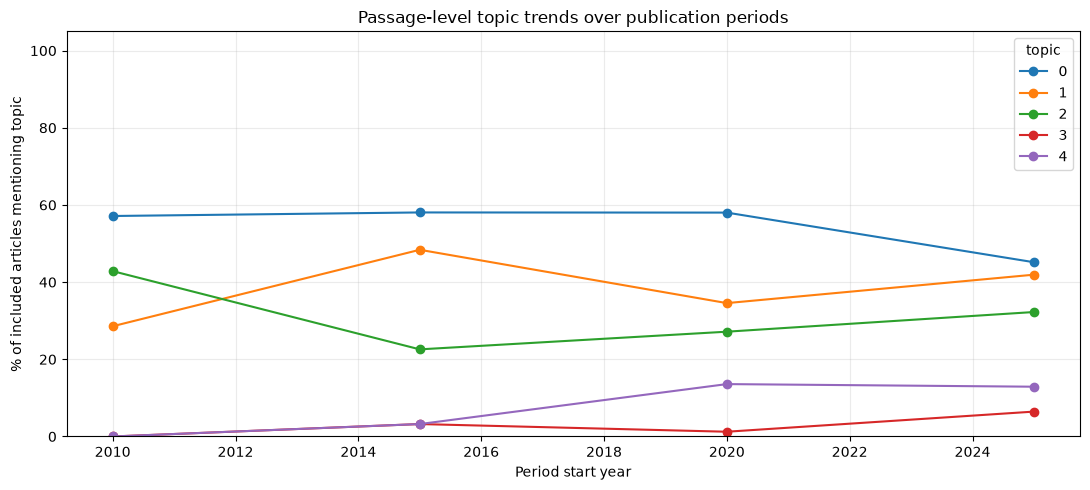

In [26]:
# Select the five most common topics, excluding outliers
top_passage_topics = (
    diagnostic_corpus.loc[diagnostic_corpus["topic"] != -1, "topic"]
    .value_counts()
    .head(5)
    .index.tolist()
)

# Calculate and visualise passage-level topic prevalence
passage_prevalence, passage_denominators = topic_prevalence_by_period(
    diagnostic_corpus,
    top_topics=top_passage_topics,
    output_dir=TOPIC_DIR,
    level="passage",
    period_years=PERIOD_YEARS,
    min_articles_per_period=5
)

In [27]:
# Count how many passages and unique articles are assigned to each topic
topic_summary = (
    diagnostic_corpus.groupby("topic")
    .agg(
        passages=("topic", "size"),
        articles=("pmcid", "nunique")
    )
    .sort_values("passages", ascending=False)
)

# Display the topic summary
display(topic_summary)

,passages,articles
topic,,
-1,740,139
0,349,83
1,153,58
2,138,42
3,132,4
...,...,...
69,15,10
70,15,3
71,15,3


In [28]:
# Count how many passages each article contributes to each topic
contributions = (
    diagnostic_corpus
    .groupby(["topic", "pmcid"])
    .size()
    .reset_index(name="passages")
)

# Show the three biggest contributing articles per topic
top_contributors = (
    contributions
    .sort_values("passages", ascending=False)
    .groupby("topic")
    .head(3)
    .sort_values(["topic", "passages"], ascending=[True, False])
)

display(top_contributors)

,topic,pmcid,passages
11,-1,PMC10496934,33
123,-1,PMC9036483,20
102,-1,PMC7827830,17
147,0,PMC10689362,20
210,0,PMC9030741,19
...,...,...,...
1103,71,PMC12188784,1
1105,72,PMC12563516,15
1107,73,PMC7827830,11
1106,73,PMC5543486,3


# Abstract/Title Level

In [29]:
# Select the abstract passages from the JATS data
abstracts = passages[
    passages["type"].fillna("").str.lower() == "abstract"
].copy()

# Sort the abstract passages into their original order
abstracts = abstracts.sort_values(["pmcid", "passage_id"])

# Combine the abstract passages into one abstract for each article
abstracts = (
    abstracts.groupby("pmcid")["text"]
    .apply(lambda x: " ".join(x.dropna().astype(str)))
    .reset_index(name="abstract")
)

# Combine the article metadata with the abstracts
# This creates one record for each article
documents_df = articles.merge(
    abstracts,
    on="pmcid",
    how="left",
    validate="one_to_one"
)

# Remove extra spaces and line breaks from the text
documents_df["title"] = documents_df["title"].map(normalise_text)
documents_df["abstract"] = documents_df["abstract"].map(normalise_text)

# Remove articles without a title or abstract
# Both are needed for the article-level embedding model
documents_df = documents_df[
    documents_df["title"].str.len().gt(0)
    & documents_df["abstract"].str.len().gt(0)
].copy()

# Combine the article title and abstract into one text document
# This will be used for article-level BERTopic
documents_df["document"] = (
    documents_df["title"] + ". " + documents_df["abstract"]
)

# Remove duplicate articles and reset the row numbers
documents_df = (
    documents_df.drop_duplicates(subset=["pmcid"])
    .reset_index(drop=True)
)

# Check how many articles are available for modelling
print("Articles for BERTopic:", len(documents_df))

# Display a few example articles
display(documents_df[["pmcid", "title", "abstract"]].head(3))


Articles for BERTopic: 149


,pmcid,title,abstract
0,PMC10052490,Autoimmune gastritis with a gastric hamartomat...,We report an unusual case of autoimmune gastri...
1,PMC10076145,Autoimmune Gastritis with a Long-term Course o...,Autoimmune gastritis (AIG) typically exhibits ...
2,PMC10241230,Gastrointestinal manifestations in autoimmune ...,SummaryAutoimmune polyendocrinopathy-candidias...


In [30]:
diagnostic_articles = filter_diagnostic_text(
    documents_df,
    PATTERN,
    text_column="document",
    min_words=MIN_WORDS
)

Diagnostic candidates: 149
Articles represented: 149


In [31]:
# Choose which embedding model to use
# If both are False, MiniLM will be used
USE_MEDCPT_QUERY = False
USE_MEDCPT_ARTICLE = True

# Set the number of documents processed in each batch
BATCH_SIZE = 8

# Set the random seed so results can be reproduced
SEED = 123

In [32]:
# Set up BERTopic using article titles and abstracts
texts, encoder, umap_model, hdbscan_model, vectorizer, min_cluster, embeddings = setup_bertopic(
    diagnostic_articles,
    text_column="document",
    use_medcpt_query=USE_MEDCPT_QUERY,
    use_medcpt_article=USE_MEDCPT_ARTICLE,
    domain_stopwords=DOMAIN_STOPWORDS,
    seed=SEED,
    batch_size=BATCH_SIZE
)

100%|██████████| 19/19 [03:02<00:00,  9.62s/it]


Embedding model: ncbi/MedCPT-Article-Encoder


In [33]:
# Fit BERTopic and assign one topic to each article
article_model, topic_articles = fit_bertopic(
    diagnostic_articles,
    texts,
    encoder,
    umap_model,
    hdbscan_model,
    vectorizer,
    embeddings=embeddings
)

2026-11-10 09:49:32,995 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-10 09:49:33,692 - BERTopic - Dimensionality - Completed ✓
2026-11-10 09:49:33,697 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-10 09:49:33,800 - BERTopic - Cluster - Completed ✓
2026-11-10 09:49:33,825 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-10 09:49:34,200 - BERTopic - Representation - Completed ✓


In [ ]:
# Evaluate the topic modelling results
n_topics, outlier_rate = evaluate_bertopic(
    topic_articles,
    model,
    min_cluster,
    level="article"
)


Discovered topics: 7
Outlier articles: 6.0%
HDBSCAN min_cluster_size: 5

Topic distribution:
topic
-1     9
 0    57
 1    34
 2    14
 3    12
 4    11
 5     7
 6     5
Name: count, dtype: int64

Articles represented per topic:
topic
-1     9
 0    57
 1    34
 2    14
 3    12
 4    11
 5     7
 6     5
Name: pmcid, dtype: int64


,Topic,Count,Name,Representation,Representative_Docs
0,-1,9,-1_amag_controls_vs_polyps,"[amag, controls, vs, polyps, malabsorption, ho...",[MON-319 A Young Woman with Familial Isolated ...
1,0,57,0_pernicious_pernicious anemia_vitamin_b12,"[pernicious, pernicious anemia, vitamin, b12, ...",[Pernicious Anemia: The Hematological Presenta...
2,1,34,1_pylori_endoscopic_case_report,"[pylori, endoscopic, case, report, hyperplasti...",[Case Report: A rare hyperplastic polyp with s...
3,2,14,2_hyperplasia_amag_cga_neuroendocrine,"[hyperplasia, amag, cga, neuroendocrine, tumor...",[Synchronous Early Gastric Cancer/Neuroendocri...
4,3,12,3_pylori_microbiota_helicobacter_infection,"[pylori, microbiota, helicobacter, infection, ...",[Polymorphism in Toll-Like Receptors and Helic...
5,4,11,4_stage_olga_stages_years,"[stage, olga, stages, years, metaplasia, gc, a...",[PREVALENCE OF GASTRIC CANCER AND PRENEOPLASTI...
6,5,7,5_combined degeneration_degeneration_combined_...,"[combined degeneration, degeneration, combined...",[Subacute Combined Degeneration of the Spinal ...
7,6,5,6_mice_hk_il17a_il27,"[mice, hk, il17a, il27, hk atpase, atpase, inf...",[Interleukin-17A Promotes Parietal Cell Atroph...


In [34]:
article_model = model
article_n_topics = n_topics

In [35]:
# Visualise the topics and inspect representative articles
inspect_bertopic(
    article_model,
    article_n_topics,
    model_name="Article - MedCPT"
)


MODEL: Article - MedCPT



TOPIC 0
The most common causes of vitamin B12 deficiency include gastrointestinal surgery (gastric bypass, ileal resection) and dietary insufficiency and less commonly from autoimmune pernicious anemia [3]. Less commonly, nitrous oxide can cause acute depletion of vitamin B12, where the majority of etiologies are chronic in nature [4]. Vitamin B12 deficiency can result in demyelination of the dorsal and lateral columns of the spinal cord causing subacute combined degeneration as evidenced by paresthesia

Vitamin B12 is an essential nutrient which plays an important role in neurological function, hematopoiesis, and DNA synthesis. Low levels usually stem from either poor intake or a malabsorptive process. Presently, the most common cause of vitamin B12 deficiency is food-bound cobalamin malabsorption, which occurs when there is impaired release of vitamin B12 from ingested food due to an outstanding factor preventing the release of the nutrient from its transport protein. Such causes in

Article coverage by period:


,period_start,period,n_articles
0,1990,1990–1994,1
1,2005,2005–2009,1
2,2010,2010–2014,7
3,2015,2015–2019,30
4,2020,2020–2024,80
5,2025,2025–2029,30


,period_start,period,topic,articles_with_topic,n_articles,pct_articles
0,2005,2005–2009,2,1,1,100.000000
1,2010,2010–2014,0,1,7,14.285714
2,2010,2010–2014,1,2,7,28.571429
3,2010,2010–2014,3,1,7,14.285714
4,2010,2010–2014,5,1,7,14.285714
5,2015,2015–2019,0,4,30,13.333333
6,2015,2015–2019,1,5,30,16.666667
7,2015,2015–2019,2,6,30,20.000000
8,2015,2015–2019,3,3,30,10.000000
9,2015,2015–2019,4,3,30,10.000000


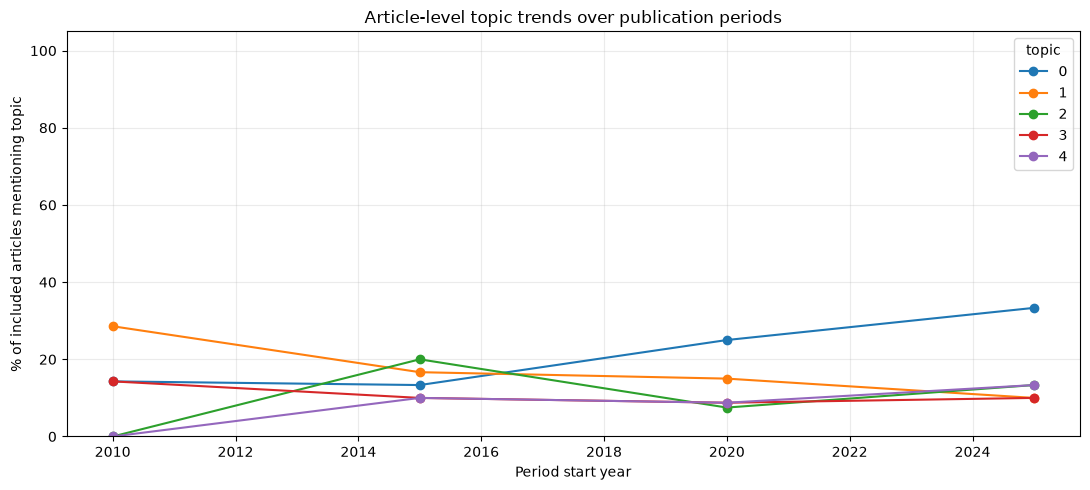

In [36]:
# Select the five most common topics, excluding outliers
top_article_topics = (
    topic_articles.loc[topic_articles["topic"] != -1, "topic"]
    .value_counts()
    .head(5)
    .index.tolist()
)

# Calculate and visualise article-level topic prevalence
article_prevalence, article_denominators = topic_prevalence_by_period(
    topic_articles,
    top_topics=top_article_topics,
    output_dir=TOPIC_DIR,
    level="article",
    period_years=PERIOD_YEARS,
    min_articles_per_period=5
)

In [37]:
# Count how many articles are assigned to each topic
topic_summary = (
    topic_articles.groupby("topic")
    .agg(
        articles=("pmcid", "nunique")
    )
    .sort_values("articles", ascending=False)
)

# Display the topic summary
display(topic_summary)

,articles
topic,
0,35
1,22
2,17
-1,14
3,14
4,14
5,13
6,7
7,7


In [38]:
# Count how many articles are assigned to each topic
contributions = (
    topic_articles
    .groupby("topic")["pmcid"]
    .nunique()
    .reset_index(name="articles")
    .sort_values("articles", ascending=False)
)

# Show the number of articles in each topic
display(contributions)

# Show three example articles from each topic
top_contributors = (
    topic_articles
    .sort_values(["topic", "pmcid"])
    .groupby("topic")
    .head(3)
    [["topic", "pmcid", "title"]]
)

display(top_contributors)

,topic,articles
1,0,35
2,1,22
3,2,17
0,-1,14
4,3,14
5,4,14
6,5,13
7,6,7
8,7,7
9,8,6


,topic,pmcid,title
7,-1,PMC10378041,Update in Molecular Aspects and Diagnosis of A...
32,-1,PMC11800024,Monitoring the follow-up of autoimmune chronic...
60,-1,PMC2191118,An autoimmune disease with multiple molecular ...
0,0,PMC10052490,Autoimmune gastritis with a gastric hamartomat...
1,0,PMC10076145,Autoimmune Gastritis with a Long-term Course o...
2,0,PMC10241230,Gastrointestinal manifestations in autoimmune ...
13,1,PMC10598509,Exploring the Association of Helicobacter pylo...
18,1,PMC10912447,Impact of autoimmune gastritis on chronic urti...
20,1,PMC11010983,Autoimmune Atrophic Gastritis: A Clinical Review
29,2,PMC11739283,Autoimmune gastritis diagnosed due to recurren...


In [39]:

# Save the results for the selected embedding model
topic_articles.to_parquet(
    TOPIC_DIR / f"{model_name.lower()}_article_topics.parquet",
    index=False
)

model.get_topic_info().to_csv(
    TOPIC_DIR / f"{model_name.lower()}_topic_info.csv",
    index=False
)